In [2]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [3]:
pd.__version__

'3.0.5'

In [3]:
load_wine().keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

In [4]:
# --- 1. Load data ---
print("Loading dataset...")
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
# add a 'target' column
df['target'] = wine.target
# print basic info (shape, first rows, summary statistics)
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
print("First 10 rows:", df.head(10))
print("Summary statistics:", df.describe())


Loading dataset...
Dataset shape: (178, 14)
Column names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']
First 10 rows:    alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   
5    14.20        1.76  2.45               15.2      112.0           3.27   
6    14.39        1.87  2.45               14.6       96.0           2.50   
7    14.06        2.15  2.61               17.6      121.0           2.60   
8    14.83    

In [5]:
# --- 2. Basic exploration ---
# print class distribution and check for missing values as well as duplicates

print("Class distribution:", df['target'].value_counts())
print("Missing values:", df.isna().sum())
print("Duplicates:", df.duplicated().sum())

Class distribution: target
1    71
0    59
2    48
Name: count, dtype: int64
Missing values: alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64
Duplicates: 0


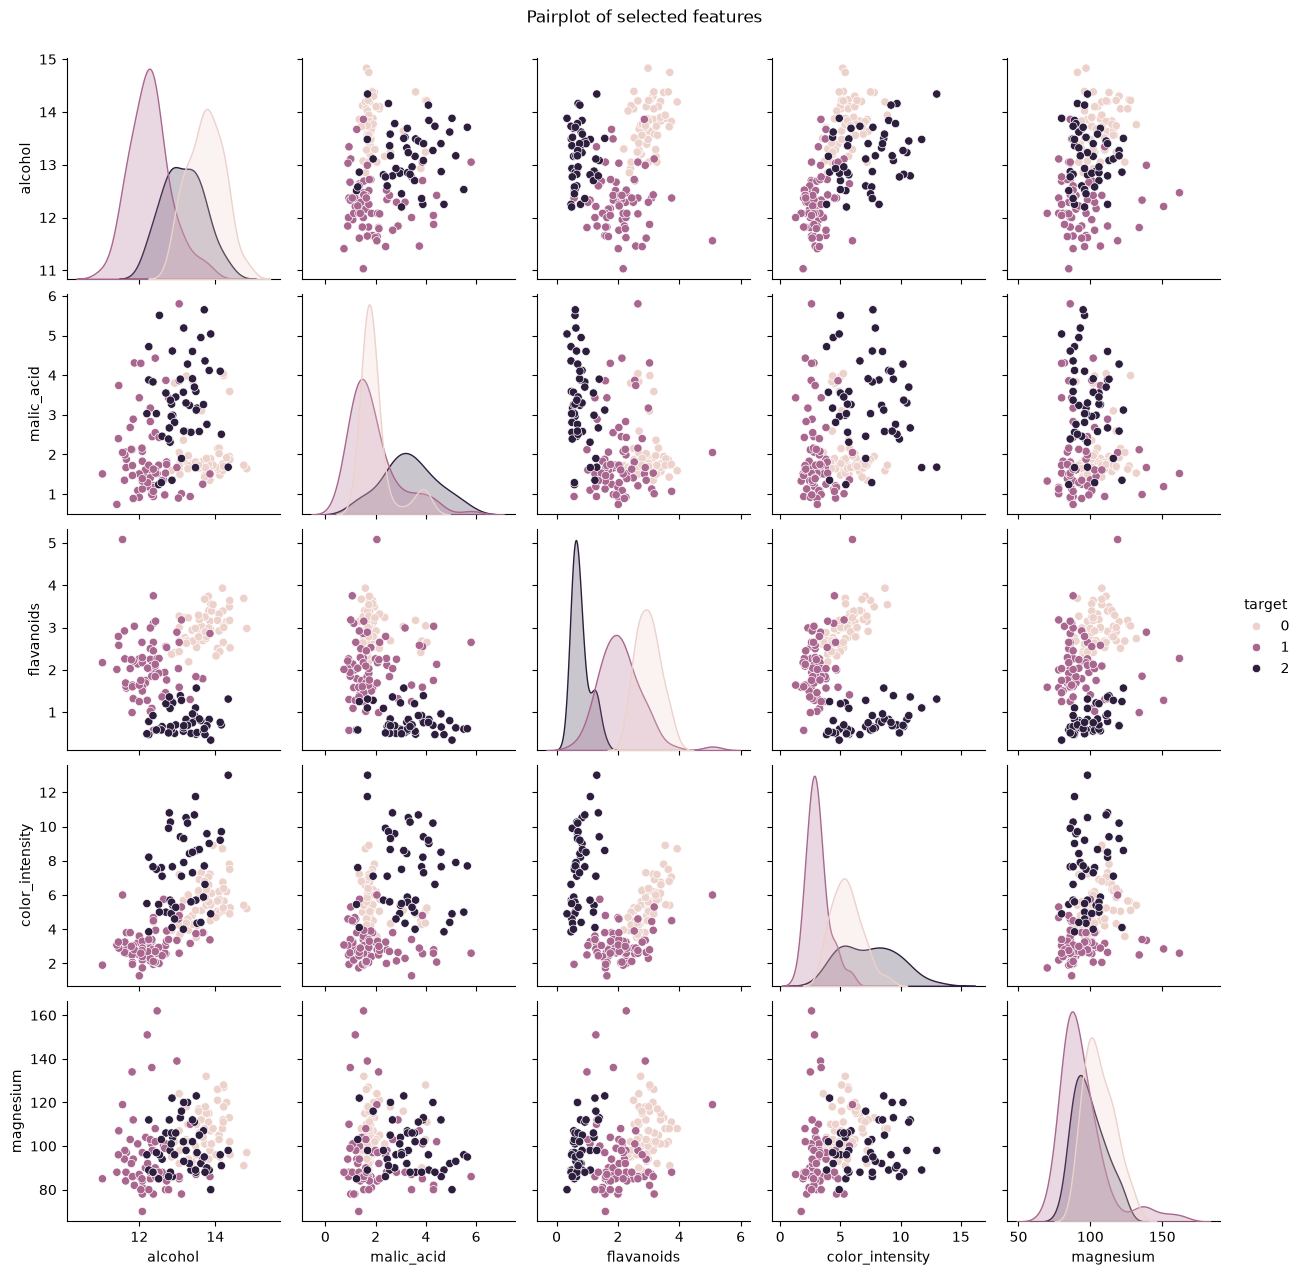

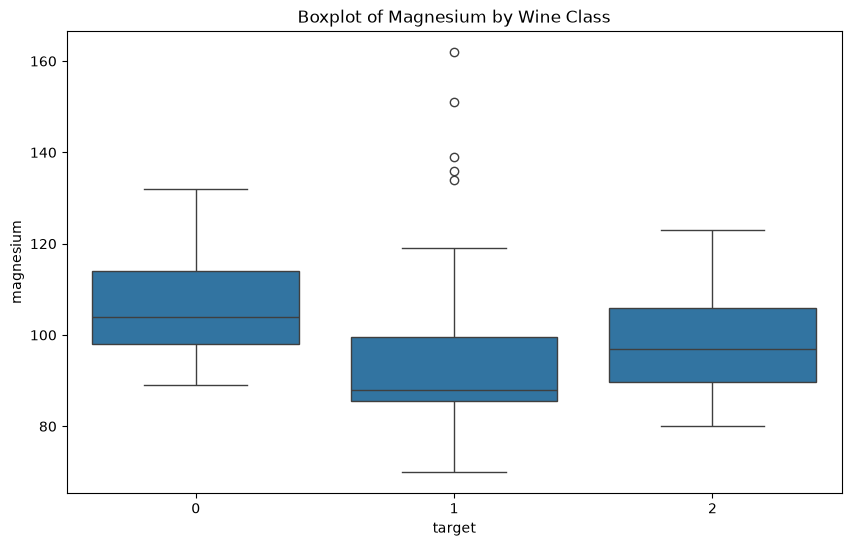

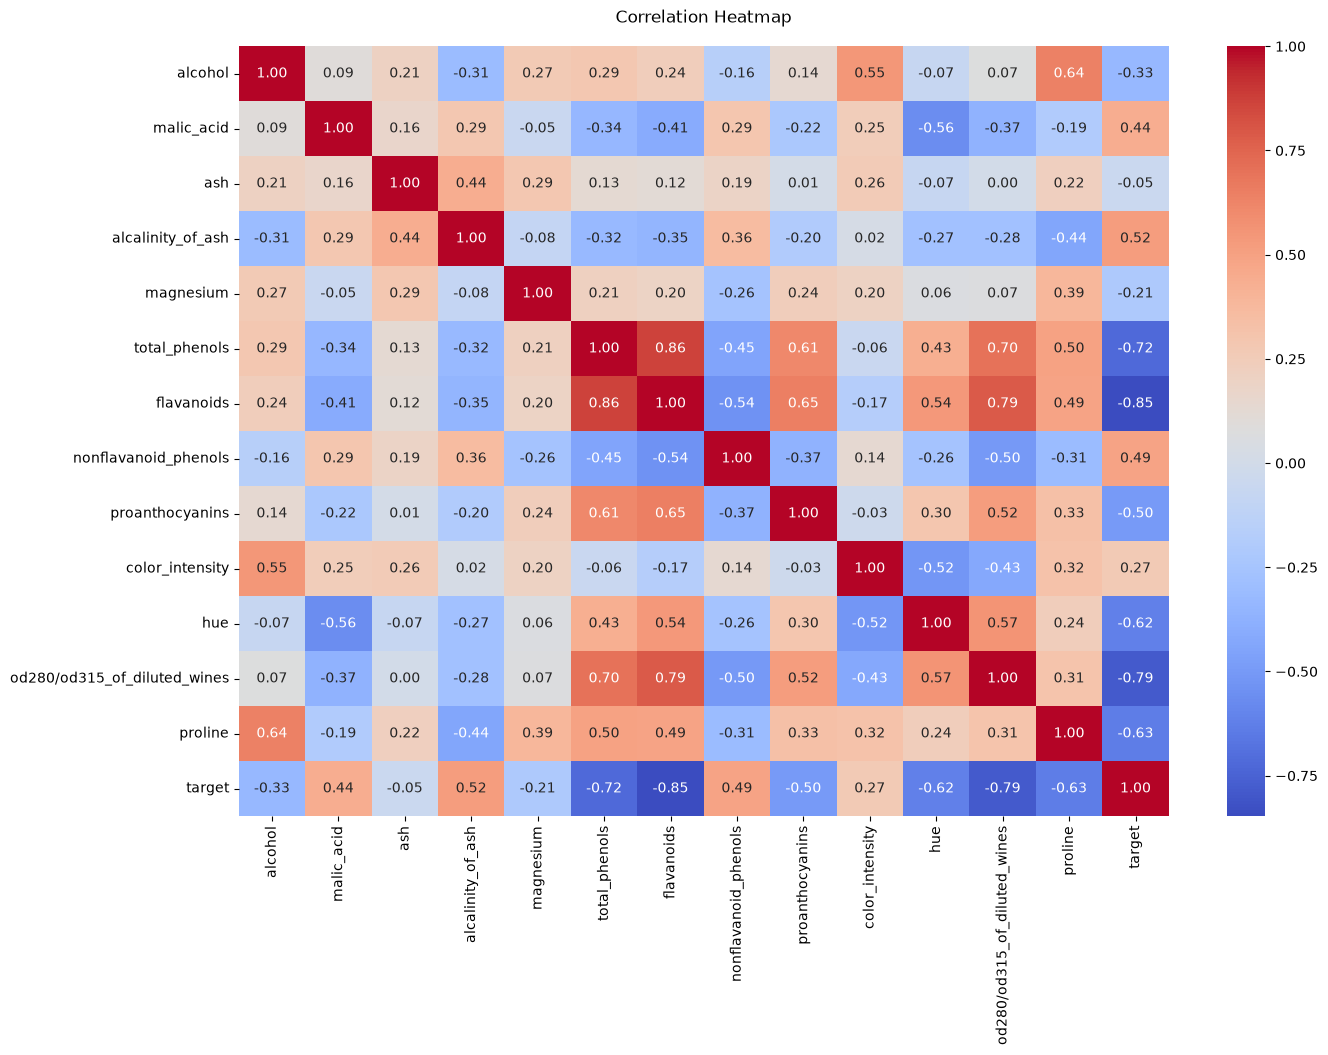

In [6]:
# --- 3. Visualisations ---
# create and save a pairplot using a few selected features
sns.pairplot(df, hue="target", vars=["alcohol", "malic_acid", "flavanoids", "color_intensity", "magnesium"])
plt.suptitle("Pairplot of selected features", y=1.02)
plt.savefig("pairplot_fig.png")




# create and save a boxplot comparing one feature across classes
plt.figure(figsize=(10, 6))
sns.boxplot(x="target", y="magnesium", data=df)
plt.title("Boxplot of Magnesium by Wine Class")
plt.savefig("boxplot_fig.png")


# plot and save a heatmap (e.g. 'heatmap.png')

plt.figure(figsize=(15,10))
sns.heatmap(df.corr(),annot= True,  cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap", y=1.02)
plt.savefig("heatmap_fig.png")


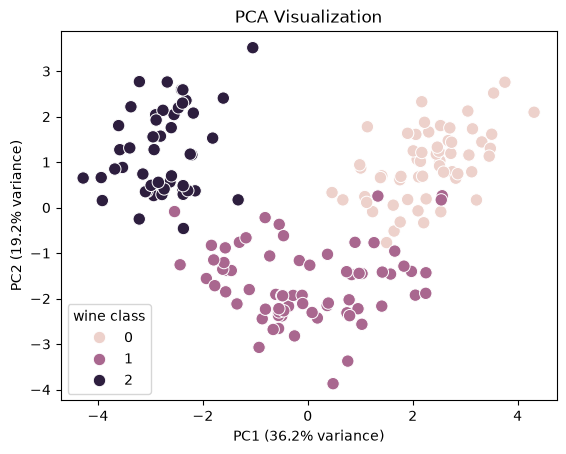

In [7]:

# --- 4. Scaling and PCA ---
# separate features (X) and target (y)
X= df.drop(["target"], axis=1)
y= df["target"]
# scale the features using StandardScaler
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
# apply PCA (2 components)
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
# create a DataFrame with PCA results and target
df_pca=pd.DataFrame(X_pca, columns=["PC1","PC2"])
df_pca["wine class"]=y
# plot and save a scatterplot of the first two components (color by target)
pca_scatterplot_fig=sns.scatterplot(data=df_pca,x="PC1", y="PC2", hue= "wine class", s=80)
plt.title("PCA Visualization")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.savefig("pca_scatterplot_fig.png")
plt.show()



Logreg train accuracy: 1.0
Logreg test accuracy: 0.9722222222222222
Tree train accuracy: 0.39436619718309857
Tree test accuracy: 0.3611111111111111


d:\Studium\UZH\BCH\DSA103\ChemicalDataScience103\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
d:\Studium\UZH\BCH\DSA103\ChemicalDataScience103\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


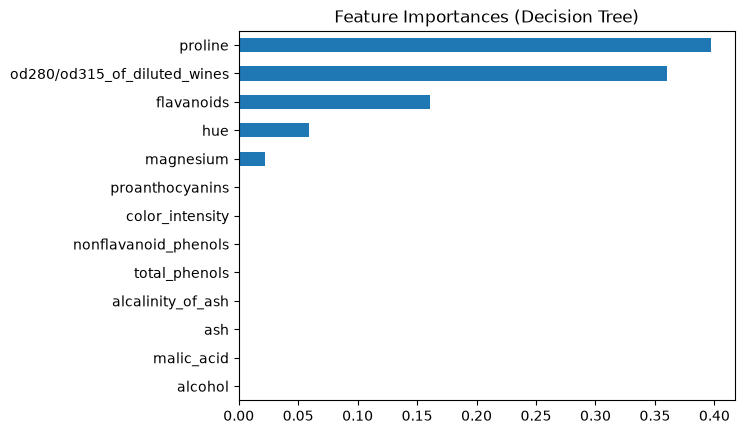

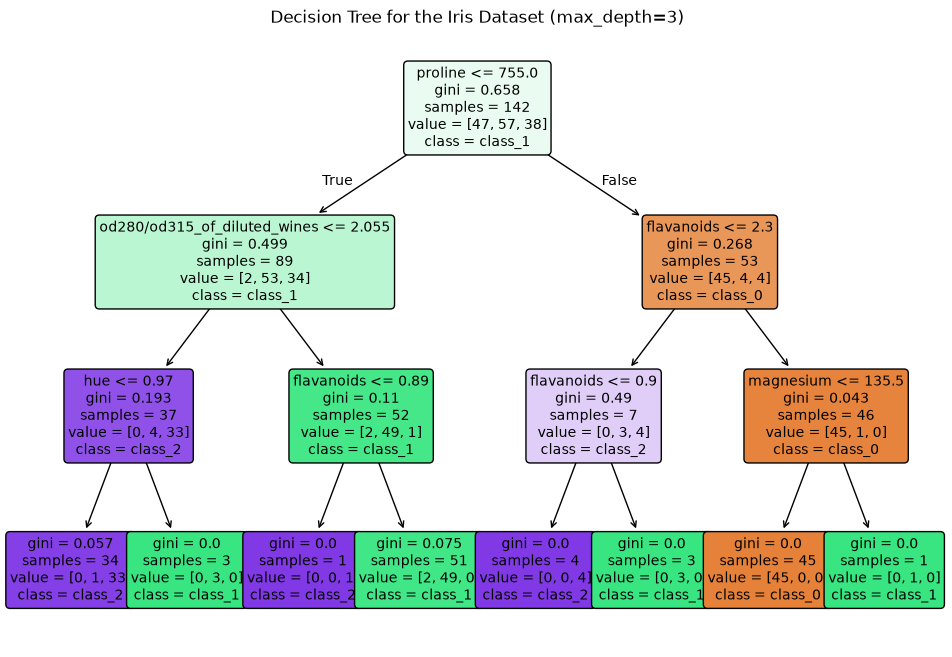

Decision Tree accuracy on 2D PCA features: 0.714126984126984


In [13]:
# --- 5. Classification models ---
#import Scikit-learn packages: 
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
# Do a random train-test split (20%) 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=52, stratify=y)
# Scale training and test features (fit_transform() on X_train, transform() on X_test)
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)
# Train logistic regression, a decision tree and a random forest (default hyperparameters)
logreg= LogisticRegression(max_iter=400)
logreg.fit(X_train_scaled, y_train)
# Compare the label prediction accuracy of the different models.
print("Logreg train accuracy:", logreg.score(X_train_scaled,y_train))
print("Logreg test accuracy:", logreg.score(X_test_scaled, y_test))

# Train and evaluate the three models on the PCA data.
## decision tree
tree=DecisionTreeClassifier(max_depth=3, random_state=52)
tree.fit(X_train, y_train)
print("Tree train accuracy:", tree.score(X_train_scaled,y_train))
print("Tree test accuracy:", tree.score(X_test_scaled, y_test))

## feature importances 
feat_importances = pd.Series(tree.feature_importances_, index=wine.feature_names)
feat_importances.sort_values().plot(kind="barh")
plt.title("Feature Importances (Decision Tree)")
plt.show()

## plot the decision tree
plt.figure(figsize=(12,8))
plot_tree(
    tree,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree for the Iris Dataset (max_depth=3)")
plt.show()


## apply to PCA features to compare predictive capabilities 
X_pca_full = PCA(n_components=2).fit_transform(X)
tree.fit(X_pca_full, y)
print("Decision Tree accuracy on 2D PCA features:", cross_val_score(tree, X_pca_full, y, cv=5).mean())
# Entry point
#if __name__ == "__main__":
#main()

In [12]:
# summary of accuracies: 

summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree (depth=3)"],
    "Train Accuracy": [logreg.score(X_train_scaled,y_train), tree.score(X_train_scaled,y_train)],
    "Test Accuracy": [logreg.score(X_test_scaled, y_test), tree.score(X_test_scaled, y_test)]
})
print(summary)

ValueError: X has 13 features, but DecisionTreeClassifier is expecting 2 features as input.